In [1]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

iris = load_iris()
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

df = pd.DataFrame(data = iris.data, columns = feature_names)
df["target"] = iris.target

In [3]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components = 3, random_state = 0).fit(iris.data)
gmm_cluster_labels = gmm.predict(iris.data)

df["gmm_cluster"] = gmm_cluster_labels

res = df.groupby(["target"])["gmm_cluster"].value_counts()
print(res)

target  gmm_cluster
0       0              50
1       2              45
        1               5
2       1              50
Name: gmm_cluster, dtype: int64


In [5]:
kmeans = KMeans(n_clusters = 3, init = "k-means++", max_iter = 300,
                random_state = 0).fit(iris.data)
kmeans_cluster_labels = kmeans.predict(iris.data)
df["kmeans_cluster"] = kmeans_cluster_labels
res = df.groupby(["target"])["kmeans_cluster"].value_counts()
print(res)

target  kmeans_cluster
0       1                 50
1       0                 48
        2                  2
2       2                 36
        0                 14
Name: kmeans_cluster, dtype: int64


In [7]:
def visualize_cluster_plot(clusterobj, dataframe, label_name,
                           iscenter = True):
    if iscenter:
        centers = clusterobj.cluster_centers_
    unique_labels = np.unique(dataframe[label_name].values)
    markers = ["o", "s", "^", "x", "*"]
    isNoise = False

    for label in unique_labels:
        label_cluster = dataframe[dataframe[label_name] == label]
        if label == -1:
            cluster_legend = "Noise"
            isNoise = True
        else:
            cluster_legend = "Cluster" + str(label)

        plt.scatter(x = label_cluster["ftr1"], y = label_cluster["ftr2"],
                    s = 70, edgecolors = "k", marker = markers[label],
                    label = cluster_legend)

        if iscenter:
            center_x_y = centers[label]
            plt.scatter(x = center_x_y[0], y = center_x_y[1], s = 250,
                        color = "white", alpha = 0.9, edgecolors = "k",
                        marker = markers[label])

            plt.scatter(x = center_x_y[0], y = center_x_y[1],
                        color = "k", edgecolors = "k",
                        marker = "$%d$" % label)
    if isNoise:
        legend_loc = "upper center"
    else:
        legend_loc = "upper right"
    plt.legend(loc = legend_loc)
    plt.show()

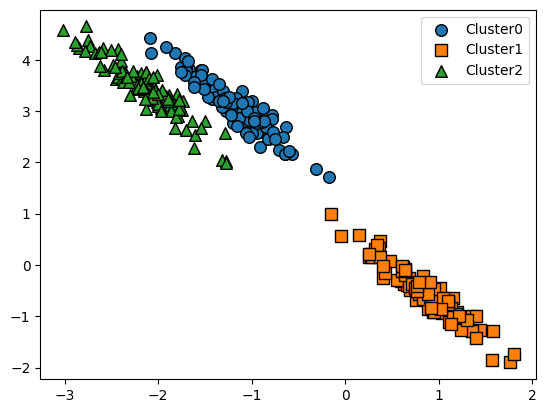

In [9]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples = 300, n_features = 2, centers = 3,
                  cluster_std = 0.5, random_state = 0)
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)
df = pd.DataFrame(data = X_aniso, columns = ["ftr1", "ftr2"])
df["target"] = y

visualize_cluster_plot(None, df, "target", iscenter = False)

In [10]:
kmeans = KMeans(3, random_state = 0)
kmeans_label = kmeans.fit_predict(X_aniso)
df["kmeans_label"] = kmeans_label

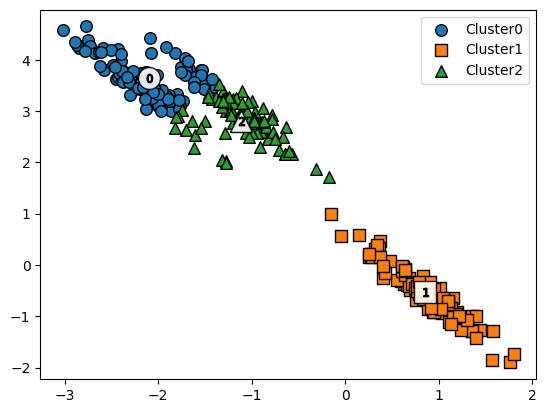

In [11]:
visualize_cluster_plot(kmeans, df, "kmeans_label", iscenter = True)

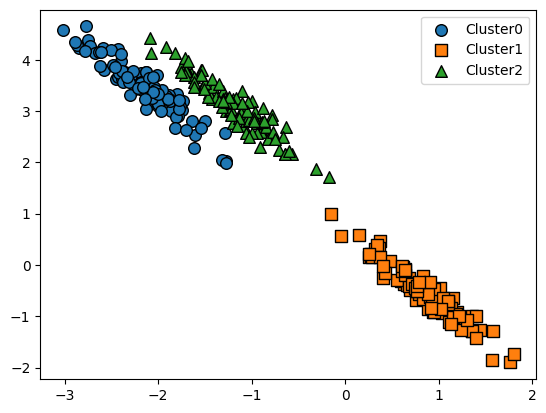

In [12]:
gmm = GaussianMixture(n_components = 3, random_state = 0)
gmm_label = gmm.fit_predict(X_aniso)
df["gmm_label"] = gmm_label

visualize_cluster_plot(gmm, df, "gmm_label", iscenter = False)

In [13]:
print(df.groupby("target")["kmeans_label"].value_counts())
print(df.groupby("target")["gmm_label"].value_counts())

target  kmeans_label
0       2                73
        0                27
1       1               100
2       0                86
        2                14
Name: kmeans_label, dtype: int64
target  gmm_label
0       2            100
1       1            100
2       0            100
Name: gmm_label, dtype: int64


In [14]:
iris = load_iris()
df = pd.DataFrame(data = iris.data, columns = feature_names)
df["target"] = iris.target
df.head()

,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [15]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps = 0.6, min_samples = 8, metric = "euclidean")
dbscan_labels = dbscan.fit_predict(iris.data)

df["dbscan_cluster"] = dbscan_labels

res = df.groupby("target")["dbscan_cluster"].value_counts()
print(res)

target  dbscan_cluster
0        0                49
        -1                 1
1        1                46
        -1                 4
2        1                42
        -1                 8
Name: dbscan_cluster, dtype: int64


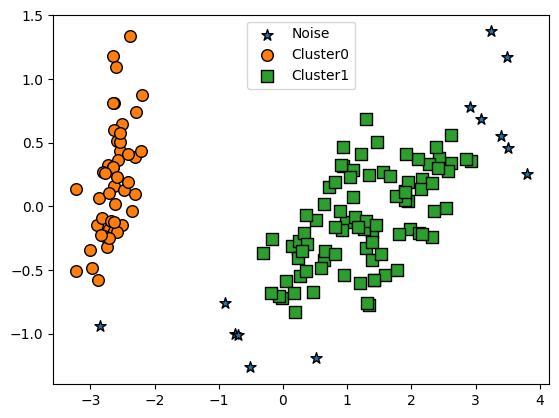

In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2, random_state = 0)
pca_transformed = pca.fit_transform(iris.data)
df["ftr1"] = pca_transformed[:, 0]
df["ftr2"] = pca_transformed[:, 1]

visualize_cluster_plot(dbscan, df, "dbscan_cluster", iscenter = False)

In [18]:
dbscan = DBSCAN(eps = 0.8, min_samples = 8, metric = "euclidean")
dbscan_labels = dbscan.fit_predict(iris.data)

df['dbscan_cluster_new'] = dbscan_labels

res = df.groupby("target")["dbscan_cluster_new"].value_counts()
print(res)

target  dbscan_cluster_new
0        0                    50
1        1                    50
2        1                    47
        -1                     3
Name: dbscan_cluster_new, dtype: int64


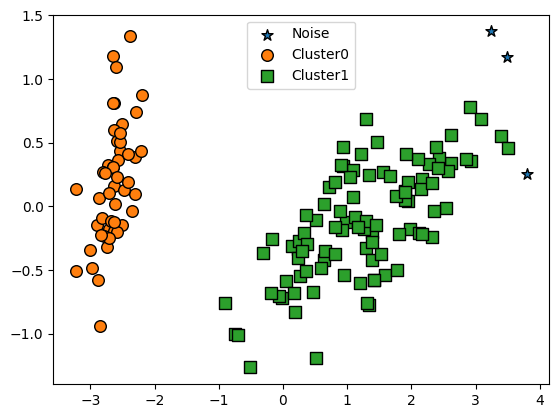

In [19]:
visualize_cluster_plot(dbscan, df, "dbscan_cluster_new", iscenter = False)

In [20]:
dbscan = DBSCAN(eps = 0.6, min_samples = 16, metric = "euclidean")
dbscan_labels = dbscan.fit_predict(iris.data)

df['dbscan_cluster_16'] = dbscan_labels

res = df.groupby("target")["dbscan_cluster_16"].value_counts()
print(res)

target  dbscan_cluster_16
0        0                   48
        -1                    2
1        1                   44
        -1                    6
2        1                   36
        -1                   14
Name: dbscan_cluster_16, dtype: int64


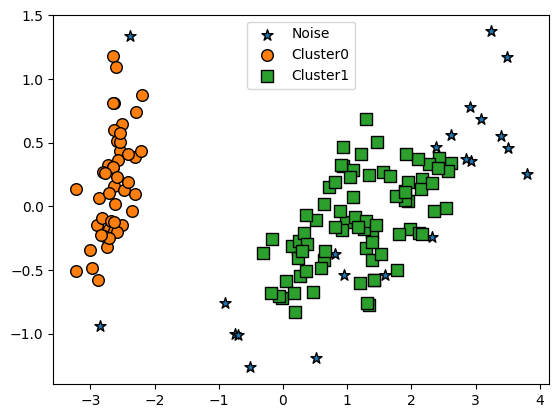

In [21]:
visualize_cluster_plot(dbscan, df, "dbscan_cluster_16", iscenter = False)

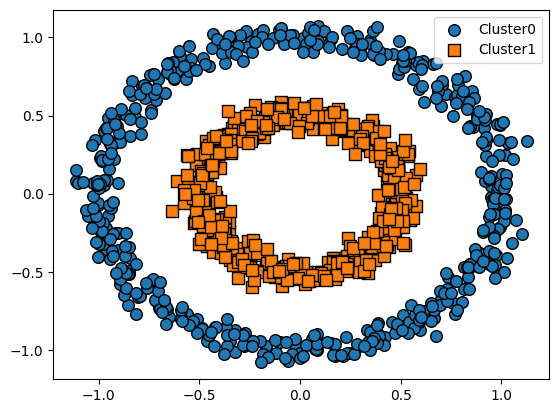

In [22]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples = 1000, shuffle = True, noise = 0.05,
                    random_state = 0, factor = 0.5)
df = pd.DataFrame(data = X, columns = ["ftr1", "ftr2"])
df["target"] = y

visualize_cluster_plot(None, df, "target", iscenter = False)

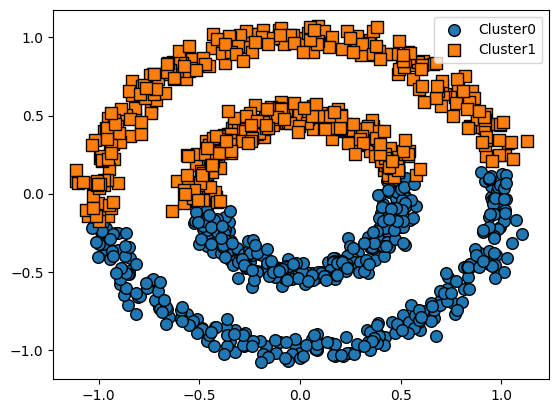

In [24]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters = 2, max_iter = 1000, random_state = 0)
kmeans_labels = kmeans.fit_predict(X)
df["kmeans_cluster"] = kmeans_labels

visualize_cluster_plot(None, df, "kmeans_cluster", iscenter = False)

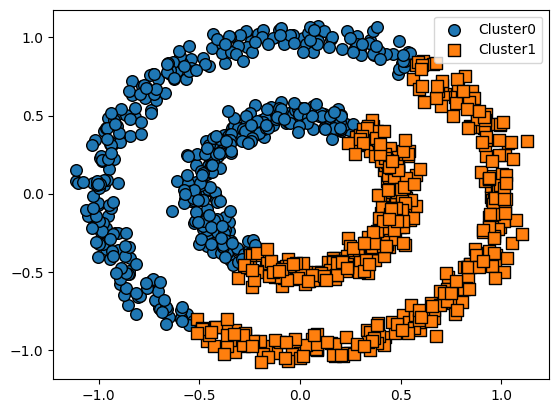

In [25]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components = 2, random_state = 0)
gmm_labels = gmm.fit_predict(X)
df["gmm_cluster"] = gmm_labels

visualize_cluster_plot(None, df, "gmm_cluster", iscenter = False)

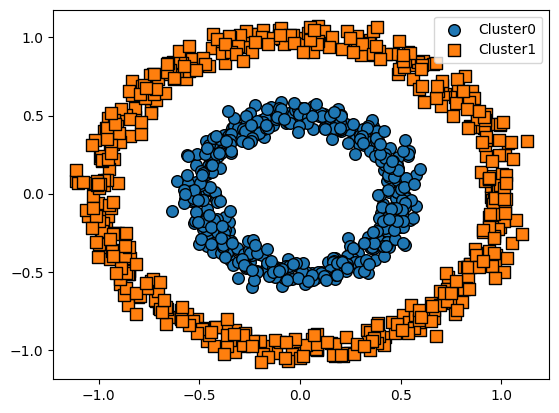

In [26]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps = 0.2, min_samples = 10, metric = "euclidean")
dbscan_labels = dbscan.fit_predict(X)
df["dbscan_cluster"] = dbscan_labels

visualize_cluster_plot(None, df, "dbscan_cluster", iscenter = False)